# Habituation: are individual whisking, licking and paw traits there before training, and do they last?

All three analyses in one place, with their figures. The code is the three scripts in this folder, split into
cells exactly as their `#%%` blocks (so the scripts stay the source; rebuild this notebook from them after editing):

| part | script | signals |
|---|---|---|
| 1 | `1_early_behaviour_stability.py` | raw: lick rate, whisker motion energy, left paw speed |
| 2 | `2_naive_pooled_stability.py` | the same, habituation + Early pooled into one naive stage |
| 3 | `3_hmm_state_measures.py` | whisking / licking HMM states (`segmentation/4.0_hmm_fit.ipynb`, `DATASET = 'habituation'`) |

Every across-mouse correlation is Spearman. The scripts print both raw ρ and lab-controlled ρ_lab (ranks
residualised on lab, p from permuting mice within lab); the figures and read-outs use raw ρ (`LAB_CONTROL = False`
at the top of each script switches the figures back). Absolute levels are comparable from habituation to Pre-rec (one camera, 30 Hz, same HMM
settings); Proficient (two cameras, 60 Hz) only by rank.

# Part 1 — raw signals at habituation

**Read-out.** Day-to-day stable (whisking ρ 0.70–0.89, paw 0.62–0.64 then 0.23, licking 0.49–0.64); carries
into Early (licking 0.80, whisking 0.82, paw 0.45). Whisker motion energy then correlates with every later stage,
Proficient included (0.47 / 0.64 / 0.48); licking reaches Late (0.58) and is gone by Proficient (0.03); paw does not
carry past Early. With lab control the whisking Proficient value drops to 0.25, so part of the long-range whisking
persistence is lab / rig. Nothing predicts learning speed.

```text
1. Is habituation behaviour stable, and does it predict behaviour later in learning?
=========================================================================================
Three raw signals per session, straight from the design matrices (no segmentation):
  lick rate   : bins with a lick event per minute ('Lick count')
  whisking    : mean whisker-pad motion energy ('whisker_me')
  paw speed   : mean speed of the left paw (l_paw_x / l_paw_y, px/s)
averaged per session, then per mouse within each timepoint.

  Habituation  data/individuality/habituation/          (habituation_design_matrix.ipynb)
  Early        design_matrices/1_camera_setup/session_1/
  Late         design_matrices/1_camera_setup/last_training/
  Pre-rec      design_matrices/1_camera_setup/biased/
  Proficient   design_matrices/                         (two-camera; left camera used)

Absolute levels are NOT comparable across timepoints: grid rate (30 vs 60 Hz), one- vs
two-camera lick merging, rig and camera geometry all differ. Only the ORDER of mice within a
timepoint is used (Spearman). Lab is the other trap: habituation and training run on the same
rig per lab, and camera geometry carries lab (see the LD1 lab-tilt result), so a
habituation-vs-training correlation can be pure rig. Every correlation is therefore also
reported lab-controlled: ranks residualised on lab, p from permuting mice within lab.

Session exclusions: left paw NaN > 20% -> no paw speed for that session (all timepoints);
habituation sessions flagged lick_ok / whisk_ok False (face out of frame) -> no lick / whisk.

@author: Ines
```

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata

HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
REPO = HERE.parent
DM = REPO / 'paper-individuality' / 'data' / 'design_matrices'
HAB = REPO / 'data' / 'individuality' / 'habituation'
FIG = HERE / 'figures'
CACHE = HERE / 'session_features.csv'      # per-session features; delete to recompute

sys.path.insert(0, str(REPO / 'paper-individuality'))
import paper_style as ps

TIMEPOINTS = {'Habituation': HAB,
              'Early': DM / '1_camera_setup' / 'session_1',
              'Late': DM / '1_camera_setup' / 'last_training',
              'Pre-rec': DM / '1_camera_setup' / 'biased',
              'Proficient': DM}
ORDER = list(TIMEPOINTS)
COLOR = {'Habituation': '#B0B0B0', **ps.TIMEPOINT}
FEATURES = {'lick_rate': 'Lick rate (bins/min)', 'whisk_me': 'Whisker motion energy',
            'paw_speed': 'Left paw speed (px/s)'}
MAX_PAW_NAN = 0.2
N_PERM = 5000
LAB_CONTROL = False   # figures: True = lab-residualised ranks and rho_lab; False = plain ranks and rho
rng = np.random.default_rng(0)

In [2]:
# ---- per-session features --------------------------------------------------------
def session_features(path):
    dm = pd.read_parquet(path)
    fs = 1 / np.median(np.diff(dm['Bin']))
    minutes = len(dm) / fs / 60
    speed = np.hypot(dm['l_paw_x'].diff(), dm['l_paw_y'].diff()) / dm['Bin'].diff()
    paw_nan = dm['l_paw_x'].isna().mean()
    return {'lick_rate': dm['Lick count'].sum() / minutes,
            'whisk_me': dm['whisker_me'].mean(),
            'paw_speed': speed.mean() if paw_nan <= MAX_PAW_NAN else np.nan,
            'paw_nan': paw_nan, 'minutes': minutes, 'fs': round(fs)}


NAME = re.compile(r'design_matrix_([0-9a-f-]{36})_(.+)$')
cached = pd.read_csv(CACHE) if CACHE.exists() else pd.DataFrame(columns=['timepoint', 'eid'])
done = set(zip(cached['timepoint'], cached['eid']))
rows = []
for tp, folder in TIMEPOINTS.items():
    for f in sorted(folder.glob('design_matrix_*')):
        m = NAME.match(f.name)
        if m and (tp, m.group(1)) not in done:
            rows.append({'timepoint': tp, 'eid': m.group(1), 'mouse_name': m.group(2),
                         **session_features(f)})
sessions = pd.concat([cached, pd.DataFrame(rows)], ignore_index=True)
sessions.to_csv(CACHE, index=False)

# Habituation: drop signals the per-signal checks flagged, and attach day + lab
hab_log = pd.read_csv(HAB / 'processing_log.csv').set_index('eid')
inventory = pd.read_csv(HERE / 'habituation_lp_sessions.csv').set_index('eid')
is_hab = sessions['timepoint'] == 'Habituation'
sessions = sessions[~is_hab | sessions['eid'].isin(hab_log.index[hab_log['status'] == 'ok'])].copy()
is_hab = sessions['timepoint'] == 'Habituation'
for flag, feat in [('lick_ok', 'lick_rate'), ('whisk_ok', 'whisk_me'), ('paw_ok', 'paw_speed')]:
    bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
    sessions.loc[bad, feat] = np.nan
sessions['hab_day'] = sessions['eid'].map(inventory['hab_day'])

lab = inventory.groupby('mouse_name')['lab'].first()     # only mice with habituation matter here
print(sessions.groupby('timepoint').agg(sessions=('eid', 'size'), mice=('mouse_name', 'nunique'),
                                        fs=('fs', 'median')).loc[ORDER].to_string())
print('\nhabituation sessions with each signal usable:',
      sessions.loc[is_hab, list(FEATURES)].notna().sum().to_dict())

# Per mouse, per timepoint
mouse = sessions.groupby(['timepoint', 'mouse_name'])[list(FEATURES)].mean()

             sessions  mice    fs
timepoint                        
Habituation       135    47  30.0
Early              49    49  30.0
Late               55    55  30.0
Pre-rec           117    44  30.0
Proficient        342   103  60.0

habituation sessions with each signal usable: {'lick_rate': 114, 'whisk_me': 121, 'paw_speed': 133}


/tmp/ipykernel_243342/2242282379.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
/tmp/ipykernel_243342/2242282379.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
/tmp/ipykernel_243342/2242282379.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the fut

In [3]:
# ---- correlation helpers ---------------------------------------------------------
def lab_residual_ranks(values, labs):
    """Ranks with each lab's mean rank removed."""
    r = pd.Series(rankdata(values), index=values.index)
    return r - r.groupby(labs.values).transform('mean')


def correlate(x, y, labs):
    """Spearman across mice, raw and lab-controlled (p by permuting mice within lab)."""
    raw = spearmanr(x, y)
    rx, ry = lab_residual_ranks(x, labs), lab_residual_ranks(y, labs)
    r_lab = np.corrcoef(rx, ry)[0, 1]
    groups = [np.where(labs.values == l)[0] for l in np.unique(labs.values)]
    ryv, null = ry.values, np.empty(N_PERM)
    for i in range(N_PERM):
        perm = np.arange(len(ryv))
        for g in groups:
            perm[g] = rng.permutation(g)
        null[i] = np.corrcoef(rx.values, ryv[perm])[0, 1]
    p_lab = (np.sum(np.abs(null) >= abs(r_lab)) + 1) / (N_PERM + 1)
    return {'n': len(x), 'n_labs': len(groups), 'rho': raw.statistic, 'p': raw.pvalue,
            'rho_lab': r_lab, 'p_lab': p_lab}


def bh(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    q = p[order] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q)
    out[order] = np.minimum(q, 1)
    return out

In [4]:
# ---- 1. stability within habituation: day to day ---------------------------------
hab = sessions[is_hab]
stab = []
for feat in FEATURES:
    wide = hab.pivot_table(index='mouse_name', columns='hab_day', values=feat)
    for a, b in [(1, 2), (2, 3), (1, 3)]:
        if a in wide and b in wide:
            pair = wide[[a, b]].dropna()
            if len(pair) >= 5:
                stab.append({'feature': feat, 'pair': f'day {a} vs {b}',
                             **correlate(pair[a], pair[b], lab.reindex(pair.index))})
stab = pd.DataFrame(stab)
print('\n== Day-to-day stability within habituation (Spearman across mice) ==')
print(stab.round(3).to_string(index=False))


== Day-to-day stability within habituation (Spearman across mice) ==
  feature       pair  n  n_labs   rho     p  rho_lab  p_lab
lick_rate day 1 vs 2 33       9 0.488 0.004    0.453  0.040
lick_rate day 2 vs 3 33       8 0.544 0.001    0.609  0.002
lick_rate day 1 vs 3 33       8 0.642 0.000    0.686  0.001
 whisk_me day 1 vs 2 36      10 0.825 0.000    0.779  0.000
 whisk_me day 2 vs 3 34       8 0.894 0.000    0.876  0.000
 whisk_me day 1 vs 3 35       8 0.700 0.000    0.633  0.002
paw_speed day 1 vs 2 40      10 0.620 0.000    0.619  0.001
paw_speed day 2 vs 3 37       9 0.644 0.000    0.491  0.012
paw_speed day 1 vs 3 37       8 0.227 0.177    0.217  0.265


In [5]:
# ---- 2. habituation vs later timepoints ------------------------------------------
cross = []
for feat in FEATURES:
    for tp in ORDER[1:]:
        both = pd.concat([mouse.loc['Habituation', feat], mouse.loc[tp, feat]], axis=1,
                         keys=['hab', 'later']).dropna()
        both = both[both.index.isin(lab.index)]
        cross.append({'feature': feat, 'timepoint': tp,
                      **correlate(both['hab'], both['later'], lab.reindex(both.index))})
cross = pd.DataFrame(cross)
cross['q'] = bh(cross['p'])
cross['q_lab'] = bh(cross['p_lab'])
print('\n== Habituation (mouse mean) vs later timepoints ==')
print(cross.round(3).to_string(index=False))

# Benchmark: the same correlation between consecutive later timepoints, on mice that
# also have habituation (so the lab control is identical).
bench = []
for feat in FEATURES:
    for a, b in [('Early', 'Late'), ('Late', 'Pre-rec'), ('Pre-rec', 'Proficient'),
                 ('Early', 'Proficient')]:
        both = pd.concat([mouse.loc[a, feat], mouse.loc[b, feat]], axis=1, keys=['a', 'b']).dropna()
        both = both[both.index.isin(lab.index)]
        if len(both) >= 5:
            bench.append({'feature': feat, 'pair': f'{a} vs {b}',
                          **correlate(both['a'], both['b'], lab.reindex(both.index))})
bench = pd.DataFrame(bench)
print('\n== Benchmark: later timepoint pairs, same mice pool ==')
print(bench.round(3).to_string(index=False))


== Habituation (mouse mean) vs later timepoints ==
  feature  timepoint  n  n_labs    rho     p  rho_lab  p_lab     q  q_lab
lick_rate      Early 31       9  0.800 0.000    0.840  0.000 0.000  0.001
lick_rate       Late 35       9  0.583 0.000    0.595  0.005 0.001  0.014
lick_rate    Pre-rec 24       6  0.197 0.357    0.225  0.379 0.464  0.505
lick_rate Proficient 35       9  0.032 0.856    0.076  0.691 0.856  0.828
 whisk_me      Early 32       9  0.815 0.000    0.762  0.000 0.000  0.001
 whisk_me       Late 36       9  0.467 0.004    0.413  0.041 0.008  0.082
 whisk_me    Pre-rec 25       6  0.636 0.001    0.461  0.040 0.002  0.082
 whisk_me Proficient 37       9  0.484 0.002    0.245  0.261 0.006  0.392
paw_speed      Early 33      10  0.453 0.008    0.334  0.122 0.014  0.209
paw_speed       Late 39      10 -0.170 0.301    0.042  0.828 0.452  0.828
paw_speed    Pre-rec 29       7  0.167 0.387    0.567  0.004 0.464  0.014
paw_speed Proficient 41      10 -0.050 0.757    0.040  0.794


== Benchmark: later timepoint pairs, same mice pool ==
  feature                  pair  n  n_labs    rho     p  rho_lab  p_lab
lick_rate         Early vs Late 32       9  0.559 0.001    0.528  0.022
lick_rate       Late vs Pre-rec 28       7  0.246 0.206   -0.038  0.863
lick_rate Pre-rec vs Proficient 29       7  0.263 0.168    0.407  0.036
lick_rate   Early vs Proficient 33      10  0.030 0.868    0.018  0.930
 whisk_me         Early vs Late 32       9  0.474 0.006    0.426  0.041
 whisk_me       Late vs Pre-rec 28       7 -0.026 0.894    0.093  0.710
 whisk_me Pre-rec vs Proficient 29       7  0.870 0.000    0.668  0.002
 whisk_me   Early vs Proficient 33      10  0.358 0.041    0.217  0.358
paw_speed         Early vs Late 32       9  0.321 0.073    0.441  0.036
paw_speed       Late vs Pre-rec 28       7  0.257 0.186    0.326  0.156
paw_speed Pre-rec vs Proficient 29       7  0.496 0.006    0.617  0.001
paw_speed   Early vs Proficient 33      10 -0.086 0.635    0.047  0.822


In [6]:
# ---- 3. habituation vs learning speed --------------------------------------------
# Learning speed = training_days, the file the rest of the paper uses (loaded as in
# learning_individuality/syllable_correlations.ipynb), with its exclusion: log_training of
# exactly 0 or 1.
training = pd.read_parquet(REPO / 'learning_prediction' / 'training_time_05-05-2026')
training['log_training'] = np.log(training['training_days'])
training = training.loc[~training['log_training'].isin([0, 1])]
speed = training.set_index('mouse_name')['training_days']
print(f'\nlearning speed: {len(speed)} mice, median {int(speed.median())} training days '
      f'(range {speed.min()}-{speed.max()})')

learn = []
for tp in ['Habituation', 'Early']:          # Early = the benchmark the paper already uses
    for feat in FEATURES:
        both = pd.concat([mouse.loc[tp, feat], np.log(speed)], axis=1, keys=['x', 'y']).dropna()
        both = both[both.index.isin(lab.index)]
        learn.append({'timepoint': tp, 'feature': feat,
                      **correlate(both['x'], both['y'], lab.reindex(both.index))})
learn = pd.DataFrame(learn)
learn['q'] = bh(learn['p'])
learn['q_lab'] = bh(learn['p_lab'])
print('\n== Behaviour vs learning speed (log training_days; + = slower learner) ==')
print(learn.round(3).to_string(index=False))


learning speed: 101 mice, median 16 training days (range 3-58)



== Behaviour vs learning speed (log training_days; + = slower learner) ==
  timepoint   feature  n  n_labs    rho     p  rho_lab  p_lab     q  q_lab
Habituation lick_rate 34       9  0.024 0.893    0.173  0.361 0.999  0.723
Habituation  whisk_me 36       9 -0.177 0.301   -0.266  0.186 0.904  0.559
Habituation paw_speed 40      10  0.000 0.999    0.111  0.556 0.999  0.835
      Early lick_rate 33      10  0.057 0.752    0.048  0.814 0.999  0.960
      Early  whisk_me 33      10 -0.270 0.128   -0.453  0.018 0.770  0.107
      Early paw_speed 33      10 -0.062 0.733    0.012  0.960 0.999  0.960


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


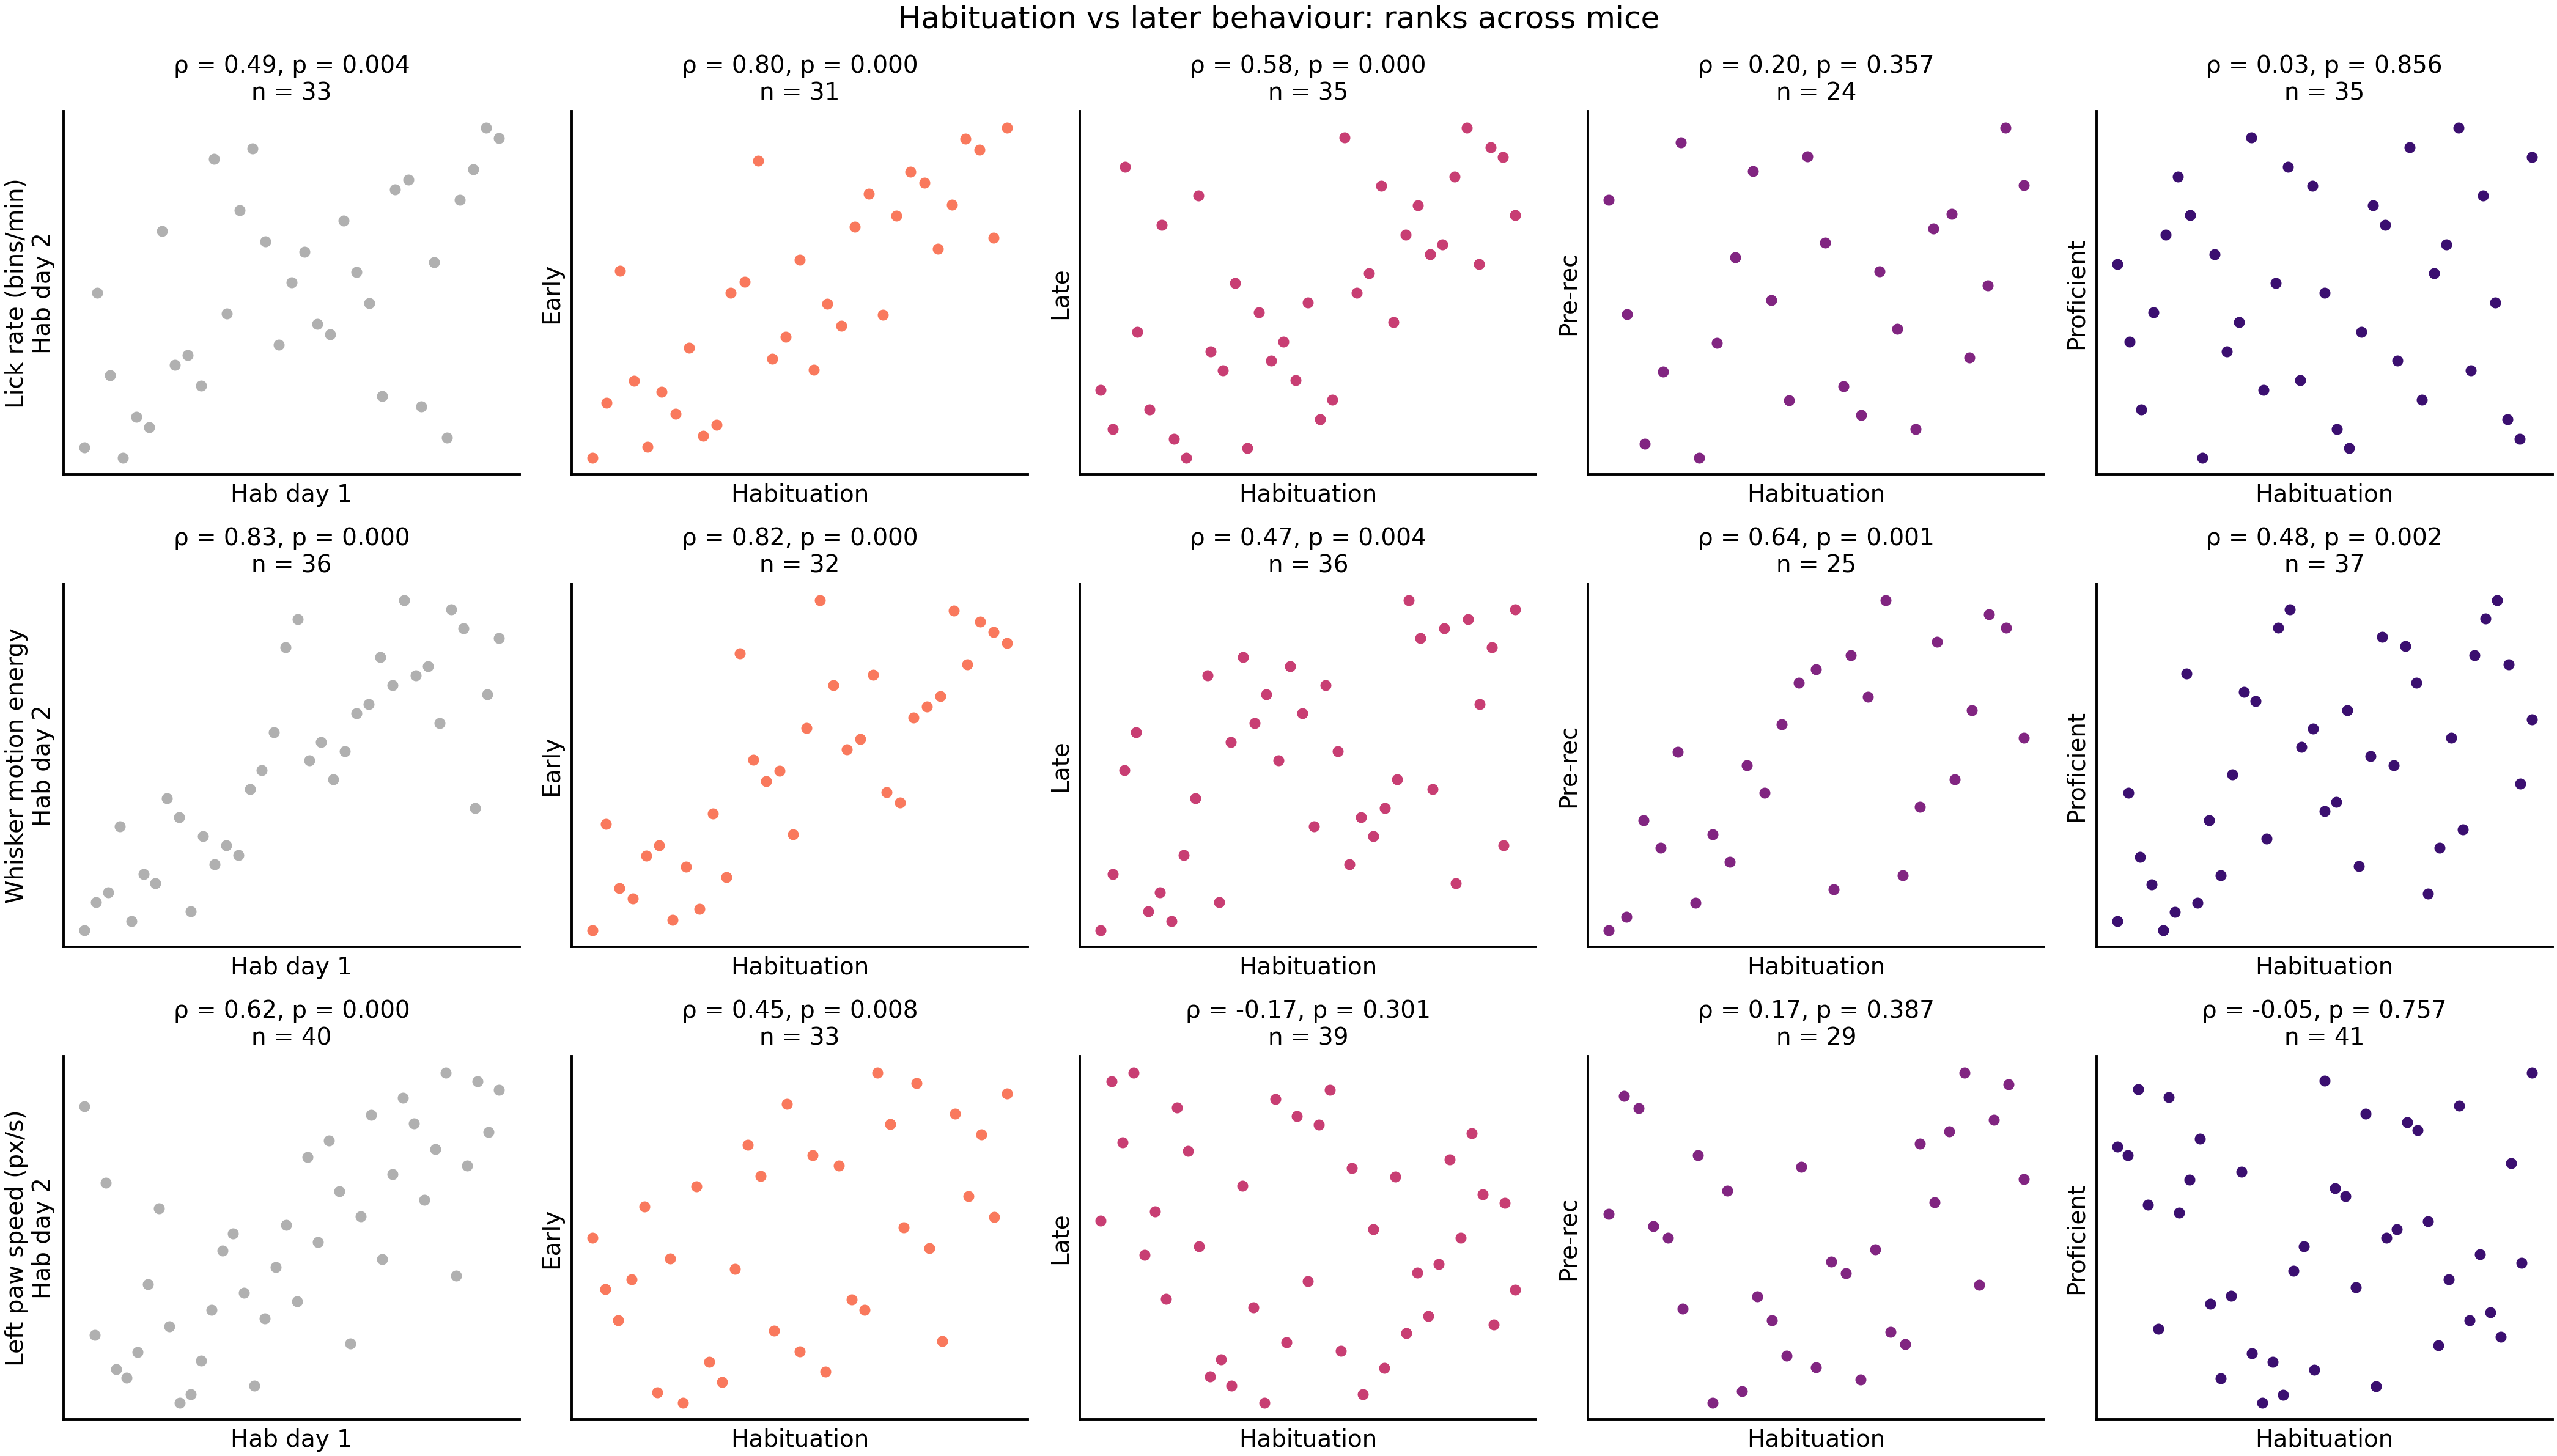

In [7]:
# ---- figure: lab-controlled ranks, habituation vs each timepoint -----------------
ps.use('paper')
fig, axes = plt.subplots(len(FEATURES), len(ORDER), figsize=(2.1 * len(ORDER), 2.0 * len(FEATURES)),
                         constrained_layout=True)
for i, feat in enumerate(FEATURES):
    # column 0: habituation day 1 vs day 2
    wide = hab.pivot_table(index='mouse_name', columns='hab_day', values=feat)
    panels = [('Habituation', wide[[1, 2]].dropna().set_axis(['x', 'y'], axis=1)
               if {1, 2} <= set(wide.columns) else pd.DataFrame(columns=['x', 'y']), 'Hab day 1', 'Hab day 2')]
    for tp in ORDER[1:]:
        both = pd.concat([mouse.loc['Habituation', feat], mouse.loc[tp, feat]], axis=1,
                         keys=['x', 'y']).dropna()
        panels.append((tp, both[both.index.isin(lab.index)], 'Habituation', tp))
    for j, (tp, d, xl, yl) in enumerate(panels):
        ax = axes[i, j]
        if len(d) >= 5:
            labs = lab.reindex(d.index)
            if LAB_CONTROL:
                rx, ry = lab_residual_ranks(d['x'], labs), lab_residual_ranks(d['y'], labs)
            else:
                rx, ry = pd.Series(rankdata(d['x']), d.index), pd.Series(rankdata(d['y']), d.index)
            ax.scatter(rx, ry, s=14, color=COLOR[tp], edgecolor='white', linewidth=0.5)
            res = correlate(d['x'], d['y'], labs)
            ax.set_title(f'ρ = {res["rho"]:.2f}, p = {res["p"]:.3f}\nn = {res["n"]}' if not LAB_CONTROL else
                         f'ρ$_{{lab}}$ = {res["rho_lab"]:.2f}, p$_{{lab}}$ = {res["p_lab"]:.3f}\nn = {res["n"]}', fontsize=7)
        if LAB_CONTROL:
            ax.axhline(0, color='0.85', lw=0.6, zorder=0)
            ax.axvline(0, color='0.85', lw=0.6, zorder=0)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(xl, fontsize=7); ax.set_ylabel(yl if j else f'{FEATURES[feat]}\n{yl}', fontsize=7)
fig.suptitle('Habituation vs later behaviour: ' + ('lab-residualised ranks' if LAB_CONTROL else 'ranks') + ' across mice', fontsize=9)
FIG.mkdir(exist_ok=True)
fig.savefig(FIG / 'habituation_stability_raw_signals.png', dpi=200)
plt.show()

# %%

# Part 2 — habituation + Early pooled (raw signals)

**Read-out.** The pooled naive score is reliable (repeatability: whisking 0.72, licking 0.61, paw 0.31), but
pooling does not extend persistence: Late / Pre-rec / Proficient correlations (whisking 0.49 / 0.60 / 0.46,
licking 0.60 / 0.21 / 0.01, paw ≈ 0) are the same as with habituation or Early alone. Three raw numbers identify the mouse across naive sessions at 20 % (chance 3 %, within-lab null 9 %).

```text
2. Habituation + Early training pooled into one NAIVE stage: are its raw-signal traits stable, and do they last?
==============================================================================================================
Same three raw per-session signals as 1_early_behaviour_stability.py (lick rate, whisker motion energy, left
paw speed; read from its cache, session_features.csv -- run that script first if it is missing), but the
habituation days and the first training session (Early) are pooled into one naive stage, so a mouse's naive
value rests on up to 4 sessions instead of 1-3.

POOLING ACROSS SESSION TYPES. Habituation and Early are both 1-camera, 30 Hz, same rig per lab, but Early has
trials and rewards, so absolute levels differ (licking above all). Each feature is therefore z-scored ACROSS
MICE within each session type (habituation day 1, 2, 3, Early) before pooling: a session contributes how the
mouse ranks against the others on that day, and a mouse's naive score is the mean of those. The same is done for
habituation alone and Early alone, so the three are comparable.

Analyses (every across-mouse correlation raw and lab-controlled, as in script 1):
  1. reliability of the naive score: repeatability R (one-way ICC over a mouse's naive sessions, lab-centred)
     and split-half (habituation-day mean vs Early, and odd vs even naive sessions), Spearman-Brown corrected;
  2. naive score vs Late, Pre-rec and Proficient (mouse means), next to habituation-only and Early-only;
  3. naive score vs learning speed (log training_days);
  4. mouse identification from the three signals across naive sessions: leave-one-session-out nearest mouse
     centroid (z-scored features), mice with >= 3 naive sessions having all three; chance = 1 / n mice, null
     from shuffling session -> mouse labels within lab.

@author: Ines
```

In [8]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata

HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
REPO = HERE.parent
HAB = REPO / 'data' / 'individuality' / 'habituation'
FIG = HERE / 'figures'
sys.path.insert(0, str(REPO / 'paper-individuality'))
import paper_style as ps

FEATURES = {'lick_rate': 'Lick rate', 'whisk_me': 'Whisker ME', 'paw_speed': 'Left paw speed'}
LATER = ['Late', 'Pre-rec', 'Proficient']
N_PERM = 5000
N_PERM_ID = 1000
rng = np.random.default_rng(0)
LAB_CONTROL = False   # figures: True = rho_lab / q_lab, False = plain Spearman rho / BH q of its p
RHO, Q = ('rho_lab', 'q_lab') if LAB_CONTROL else ('rho', 'q')

In [9]:
# ---- sessions: the cache of script 1, with its habituation exclusions -----------
sessions = pd.read_csv(HERE / 'session_features.csv')
hab_log = pd.read_csv(HAB / 'processing_log.csv').set_index('eid')
inventory = pd.read_csv(HERE / 'habituation_lp_sessions.csv').set_index('eid')
is_hab = sessions['timepoint'] == 'Habituation'
sessions = sessions[~is_hab | sessions['eid'].isin(hab_log.index[hab_log['status'] == 'ok'])].copy()
is_hab = sessions['timepoint'] == 'Habituation'
for flag, feat in [('lick_ok', 'lick_rate'), ('whisk_ok', 'whisk_me'), ('paw_ok', 'paw_speed')]:
    bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
    sessions.loc[bad, feat] = np.nan
sessions['hab_day'] = sessions['eid'].map(inventory['hab_day'])
lab = inventory.groupby('mouse_name')['lab'].first()        # mice with habituation sessions

# session type for the naive stage: habituation day 1-3 (day 4: 8 mice, folded into day 3) or Early
naive = sessions[sessions['timepoint'].isin(['Habituation', 'Early']) & sessions['mouse_name'].isin(lab.index)].copy()
naive['stype'] = np.where(naive['timepoint'] == 'Early', 'Early',
                          'hab' + naive['hab_day'].clip(upper=3).astype('Int64').astype(str))
for f in FEATURES:      # z across mice within each session type (each mouse once per type: mean if repeated)
    naive[f + '_z'] = naive.groupby('stype')[f].transform(lambda v: (v - v.mean()) / v.std())
Z = [f + '_z' for f in FEATURES]
print(naive.groupby('stype').agg(sessions=('eid', 'size'), mice=('mouse_name', 'nunique')).to_string())
print('naive sessions per mouse:', naive.groupby('mouse_name').size().describe().round(1).to_dict())

def score(d):
    return d.groupby('mouse_name')[Z].mean().rename(columns=dict(zip(Z, FEATURES)))

STAGES = {'Naive (hab + Early)': score(naive),
          'Habituation only': score(naive[naive['stype'] != 'Early']),
          'Early only': score(naive[naive['stype'] == 'Early'])}
later = sessions[sessions['timepoint'].isin(LATER)].groupby(['timepoint', 'mouse_name'])[list(FEATURES)].mean()

       sessions  mice
stype                
Early        33    33
hab1         47    47
hab2         41    41
hab3         47    39
naive sessions per mouse: {'count': 47.0, 'mean': 3.6, 'std': 0.9, 'min': 1.0, '25%': 3.0, '50%': 4.0, '75%': 4.0, 'max': 5.0}


/tmp/ipykernel_243342/1967836915.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
/tmp/ipykernel_243342/1967836915.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  bad = is_hab & ~sessions['eid'].map(hab_log[flag]).fillna(False).astype(bool)
/tmp/ipykernel_243342/1967836915.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future

In [10]:
# ---- helpers (as in script 1) ----------------------------------------------------
def lab_residual_ranks(values, labs):
    r = pd.Series(rankdata(values), index=values.index)
    return r - r.groupby(labs.values).transform('mean')

def correlate(x, y, labs, n_perm=N_PERM):
    raw = spearmanr(x, y)
    rx, ry = lab_residual_ranks(x, labs), lab_residual_ranks(y, labs)
    r_lab = np.corrcoef(rx, ry)[0, 1]
    groups = [np.where(labs.values == l)[0] for l in np.unique(labs.values)]
    ryv, null = ry.values, np.empty(n_perm)
    for i in range(n_perm):
        perm = np.arange(len(ryv))
        for g in groups:
            perm[g] = rng.permutation(g)
        null[i] = np.corrcoef(rx.values, ryv[perm])[0, 1]
    return {'n': len(x), 'rho': raw.statistic, 'p': raw.pvalue, 'rho_lab': r_lab,
            'p_lab': (np.sum(np.abs(null) >= abs(r_lab)) + 1) / (n_perm + 1)}

def bh(p):
    p = np.asarray(p, float); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q, 1)
    return out

def icc(values, groups):
    """One-way ANOVA repeatability (unbiased, as non_emerging/session_metric_individuality)."""
    v = np.asarray(values, float); ok = np.isfinite(v); v = v[ok]
    g = pd.factorize(np.asarray(groups)[ok])[0]
    M_, N_ = g.max() + 1, len(v)
    n = np.bincount(g).astype(float); mu = np.bincount(g, weights=v) / n
    keep = n >= 2
    ms_w = ((v - mu[g]) ** 2).sum() / (N_ - M_)
    ms_b = (n * (mu - v.mean()) ** 2).sum() / (M_ - 1)
    n0 = (N_ - (n ** 2).sum() / N_) / (M_ - 1)
    s2 = (ms_b - ms_w) / n0
    return max(s2, 0) / (max(s2, 0) + ms_w), int(keep.sum())

In [11]:
# ---- 1. reliability of the naive score -------------------------------------------
rel = []
for f, z in zip(FEATURES, Z):
    d = naive.dropna(subset=[z])
    d = d[d.groupby('mouse_name')[z].transform('size') >= 2]
    centred = d[z] - d.groupby(d['mouse_name'].map(lab))[z].transform('mean')    # lab-centred
    R, n_m = icc(centred, d['mouse_name'])
    # split halves: habituation mean vs Early; odd vs even sessions (chronological within mouse)
    h = d[d['stype'] != 'Early'].groupby('mouse_name')[z].mean()
    e = d[d['stype'] == 'Early'].groupby('mouse_name')[z].mean()
    he = pd.concat([h, e], axis=1, keys=['a', 'b']).dropna()
    d = d.sort_values(['mouse_name', 'stype'])
    k = d.groupby('mouse_name').cumcount()
    oe = pd.concat([d[k % 2 == 0].groupby('mouse_name')[z].mean(), d[k % 2 == 1].groupby('mouse_name')[z].mean()],
                   axis=1, keys=['a', 'b']).dropna()
    for name, pair in [('habituation vs Early', he), ('odd vs even sessions', oe)]:
        c = correlate(pair['a'], pair['b'], lab.reindex(pair.index))
        rel.append(dict(feature=f, test=name, R_naive=R, mice_R=n_m, **c,
                        spearman_brown=2 * c['rho_lab'] / (1 + c['rho_lab']) if c['rho_lab'] > -1 else np.nan))
rel = pd.DataFrame(rel)
print('\n== 1. Reliability of the naive score (lab-controlled) ==')
print(rel.round(3).to_string(index=False))


== 1. Reliability of the naive score (lab-controlled) ==
  feature                 test  R_naive  mice_R  n   rho    p  rho_lab  p_lab  spearman_brown
lick_rate habituation vs Early    0.605      40 31 0.776 0.00    0.835  0.000           0.910
lick_rate odd vs even sessions    0.605      40 40 0.673 0.00    0.636  0.001           0.777
 whisk_me habituation vs Early    0.717      43 32 0.820 0.00    0.766  0.001           0.867
 whisk_me odd vs even sessions    0.717      43 43 0.905 0.00    0.883  0.000           0.938
paw_speed habituation vs Early    0.312      46 33 0.445 0.01    0.326  0.125           0.492
paw_speed odd vs even sessions    0.312      46 46 0.639 0.00    0.560  0.003           0.718


In [12]:
# ---- 2. naive vs later stages ------------------------------------------------------
cross = []
for stage, S in STAGES.items():
    for f in FEATURES:
        for tp in LATER:
            both = pd.concat([S[f], later.loc[tp, f]], axis=1, keys=['x', 'y']).dropna()
            both = both[both.index.isin(lab.index)]
            if len(both) >= 5:
                cross.append(dict(stage=stage, feature=f, later=tp, **correlate(both['x'], both['y'], lab.reindex(both.index))))
cross = pd.DataFrame(cross)
cross['q_lab'] = cross.groupby('stage')['p_lab'].transform(bh)
cross['q'] = cross.groupby('stage')['p'].transform(bh)
print('\n== 2. Naive score vs later stages (rho_lab; q_lab = BH within each stage row family) ==')
print(cross.pivot_table(index=['feature', 'later'], columns='stage', values='rho_lab').round(2).to_string())
print(cross[cross['stage'] == 'Naive (hab + Early)'].round(3).to_string(index=False))


== 2. Naive score vs later stages (rho_lab; q_lab = BH within each stage row family) ==
stage                 Early only  Habituation only  Naive (hab + Early)
feature   later                                                        
lick_rate Late              0.53              0.62                 0.61
          Pre-rec           0.11              0.22                 0.23
          Proficient        0.02              0.07                 0.02
paw_speed Late              0.44              0.04                 0.15
          Pre-rec           0.13              0.57                 0.43
          Proficient        0.05              0.03                -0.05
whisk_me  Late              0.43              0.41                 0.44
          Pre-rec           0.49              0.48                 0.43
          Proficient        0.22              0.25                 0.25
              stage   feature      later  n    rho     p  rho_lab  p_lab  q_lab     q
Naive (hab + Early) lick_rate    

In [13]:
# ---- 3. naive vs learning speed -----------------------------------------------------
training = pd.read_parquet(REPO / 'learning_prediction' / 'training_time_05-05-2026')
training['log_training'] = np.log(training['training_days'])
training = training.loc[~training['log_training'].isin([0, 1])]
speed = np.log(training.set_index('mouse_name')['training_days'])
learn = []
for stage, S in STAGES.items():
    for f in FEATURES:
        both = pd.concat([S[f], speed], axis=1, keys=['x', 'y']).dropna()
        both = both[both.index.isin(lab.index)]
        learn.append(dict(stage=stage, feature=f, **correlate(both['x'], both['y'], lab.reindex(both.index))))
learn = pd.DataFrame(learn)
learn['q_lab'] = bh(learn['p_lab'])
print('\n== 3. Naive score vs learning speed (log training days; + = slower) ==')
print(learn.round(3).to_string(index=False))


== 3. Naive score vs learning speed (log training days; + = slower) ==
              stage   feature  n    rho     p  rho_lab  p_lab  q_lab
Naive (hab + Early) lick_rate 36  0.023 0.896    0.048  0.779  0.894
Naive (hab + Early)  whisk_me 37 -0.197 0.242   -0.311  0.121  0.543
Naive (hab + Early) paw_speed 40 -0.029 0.860    0.104  0.565  0.894
   Habituation only lick_rate 34  0.019 0.915    0.080  0.689  0.894
   Habituation only  whisk_me 36 -0.170 0.321   -0.264  0.192  0.576
   Habituation only paw_speed 40  0.006 0.972    0.120  0.523  0.894
         Early only lick_rate 33  0.057 0.752    0.048  0.795  0.894
         Early only  whisk_me 33 -0.270 0.128   -0.453  0.021  0.185
         Early only paw_speed 33 -0.062 0.733    0.012  0.957  0.957


In [14]:
# ---- 4. mouse identification across naive sessions ---------------------------------
def nearest_centroid_loso(X, y):
    hits = np.zeros(len(X), bool)
    for i in range(len(X)):
        tr = np.arange(len(X)) != i
        mice = np.unique(y[tr])
        C = np.stack([X[tr][y[tr] == m].mean(0) for m in mice])
        hits[i] = mice[np.argmin(((C - X[i]) ** 2).sum(1))] == y[i]
    return hits.mean()

idd = naive.dropna(subset=Z)
idd = idd[idd.groupby('mouse_name')['eid'].transform('size') >= 3]
X, y = idd[Z].to_numpy(), idd['mouse_name'].to_numpy()
labs_s = idd['mouse_name'].map(lab).to_numpy()
acc = nearest_centroid_loso(X, y)
null = []
for _ in range(N_PERM_ID):
    yp = y.copy()
    for l in np.unique(labs_s):          # shuffle sessions between mice of the same lab
        idx = np.where(labs_s == l)[0]
        yp[idx] = rng.permutation(yp[idx])
    null.append(nearest_centroid_loso(X, yp))
null = np.array(null)
ID = dict(accuracy=acc, n_sessions=len(X), n_mice=len(np.unique(y)), chance=1 / len(np.unique(y)),
          null_within_lab=null.mean(), p=(np.sum(null >= acc) + 1) / (len(null) + 1))
print('\n== 4. Mouse identification from the 3 raw signals, naive sessions ==')
print({k: round(v, 4) if isinstance(v, float) else v for k, v in ID.items()})


== 4. Mouse identification from the 3 raw signals, naive sessions ==
{'accuracy': np.float64(0.203), 'n_sessions': 133, 'n_mice': 35, 'chance': 0.0286, 'null_within_lab': np.float64(0.0923), 'p': np.float64(0.001)}


paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


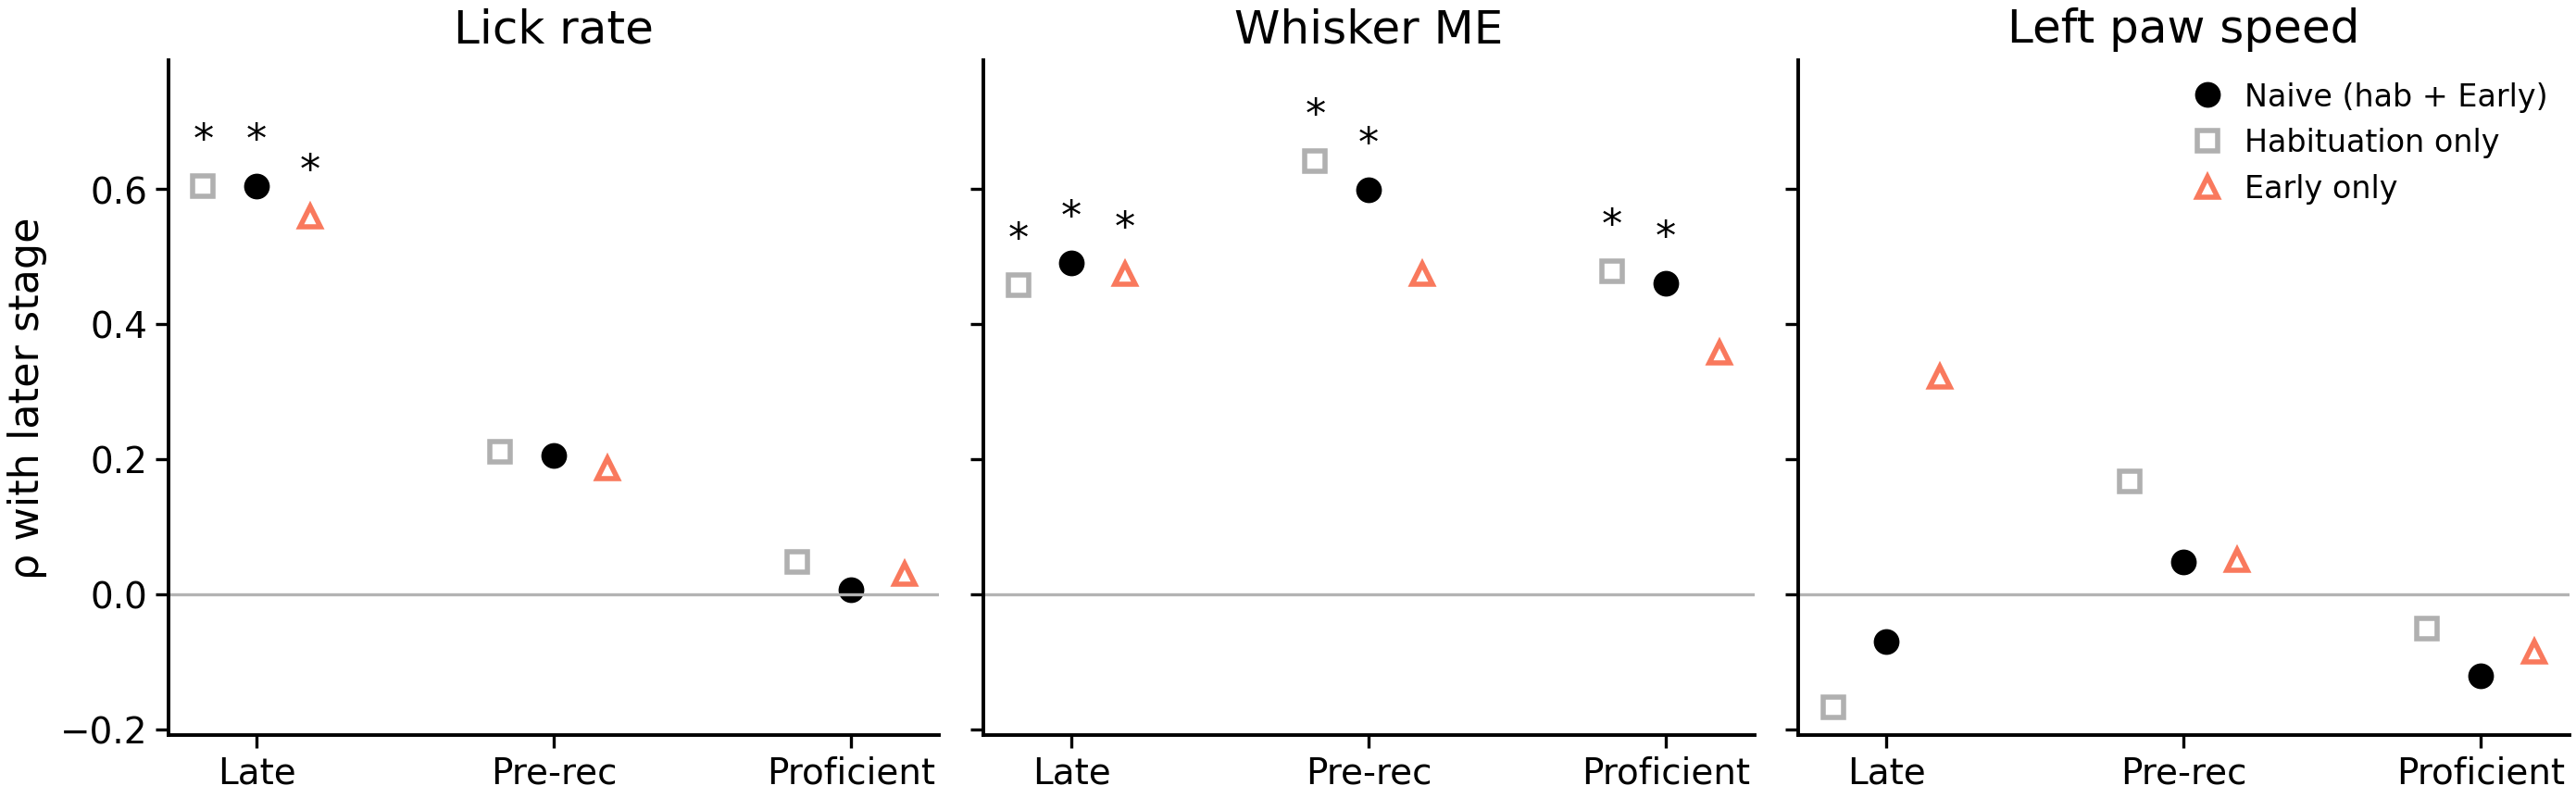

In [15]:
# ---- figure: rho (or rho_lab, see LAB_CONTROL) per feature x later stage, naive vs hab-only vs Early-only -------
ps.use('paper')
fig, axes = plt.subplots(1, len(FEATURES), figsize=(7.0, 2.2), sharey=True, constrained_layout=True)
style = {'Naive (hab + Early)': ('k', 'o', 0), 'Habituation only': ('#B0B0B0', 's', -0.18),
         'Early only': (ps.TIMEPOINT['Early'], '^', 0.18)}
for ax, f in zip(axes, FEATURES):
    for stage, (col, mk, dx) in style.items():
        d = cross[(cross['stage'] == stage) & (cross['feature'] == f)].set_index('later').reindex(LATER)
        x = np.arange(len(LATER)) + dx
        ax.plot(x, d[RHO], mk, color=col, ms=4, mfc=col if stage.startswith('Naive') else 'white', label=stage)
        for xi, (r_, q_) in zip(x, d[[RHO, Q]].to_numpy()):
            if q_ < 0.05:
                ax.text(xi, r_ + 0.05, '*', ha='center', fontsize=8)
    ax.axhline(0, color='0.7', lw=0.6)
    ax.set_xticks(range(len(LATER))); ax.set_xticklabels(LATER)
    ax.set_title(FEATURES[f])
axes[0].set_ylabel('ρ with later stage' + ('\n(lab-controlled)' if LAB_CONTROL else ''))
axes[0].set_ylim(top=cross[RHO].max() + 0.15)   # room for the stars
axes[-1].legend(frameon=False, fontsize=6, loc='upper right')
FIG.mkdir(exist_ok=True)
fig.savefig(FIG / 'naive_pooled_vs_later.png', dpi=200)
plt.show()

# Part 3 — whisking and licking HMM states at habituation

**Fits.** Whisking 121/121 pass every screen (median bout 600 ms). Licking: 87/114 pass as written; the 27
'degenerate' ones are near-silent sessions (median 4.5 lick bins / min vs 37) and are kept (2 collapsed = no licking).

**Read-out.** Fraction of time and bout rate are stable across habituation days (ρ ~0.5–0.7, except whisking bout rate on days 1→2, 0.25); whisking bout
duration is too (0.62, into Early 0.48), licking bout duration is not. Six state measures identify the mouse at 31 % (within-lab null 10 %). Fraction of time licking carries into
Late (0.47); fraction of time whisking only into Early (0.60, then ≈ 0); whisking bout rate stays ~0.3–0.4 to
Proficient but only Early passes FDR. Raw whisker motion energy lasted to Proficient, so the lasting whisking trait is probably intensity, which the per-session z-scored whisking HMM removes
(a reading, not yet tested). Licking rises with training in absolute terms (fraction 0.08 → 0.18).

```text
3. Whisking and licking STATES at habituation: are their amount and timing individual, and do they last?
=====================================================================================================
The 2-state whisking (Gaussian, z-scored whisker ME, 30 Hz) and licking (Poisson, 100 ms bins) HMMs of
segmentation/4.0_hmm_fit.ipynb (DATASET = 'habituation'), fitted on habituation sessions only. The 1-camera
training stages (Early = session_1, Late = last_training, Pre-rec = biased) were fitted with the SAME settings
(data/training/hmm/), so their measures are comparable to habituation in absolute terms; Proficient was fitted
from the 2-camera, 60 Hz data with the unbinned lick HMM (data/hmm/), so it is compared by RANK only.

Per session, per signal (state 1 = whisking / licking; no trial alignment -- habituation has no reliable trials):
  frac      fraction of time in the active state
  bout_rate active bouts per minute
  bout_dur  median active-bout duration (s)
Whisking: only fits passing the pipeline's screens (fit_ok). Licking: 'degenerate occupancy' / 'collapsed' fits
are near-silent sessions, not failures, so they are kept (collapsed = no licking); flickering / failed fits dropped. Bouts are counted within contiguous stretches of frames (a gap in the frame times ends a bout).

Analyses (Spearman across mice, raw and lab-controlled, as in 1_early_behaviour_stability.py):
  1. day-to-day stability within habituation (day 1 vs 2, 2 vs 3, 1 vs 3);
  2. mouse identification across habituation sessions from the six measures (leave-one-session-out nearest
     centroid, z-scored; null = shuffling sessions between mice of the same lab);
  3. habituation (mouse mean) vs Early, Late, Pre-rec (absolute level and rank) and Proficient (rank only).

@author: Ines
```

In [16]:
import re
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, wilcoxon

HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
REPO = HERE.parent
PI = REPO / 'paper-individuality'
DM = PI / 'data' / 'design_matrices'
FIG = HERE / 'figures'
CACHE = HERE / 'hmm_state_measures.csv'      # per-session measures; delete to recompute
sys.path.insert(0, str(PI))
import paper_style as ps

TAG = {'whisker_me': '5_gaussian_kmeans_em_zsc_True_k0_s2',
       'Lick count': '5_poisson_prior_em_zsc_False_k0_s2_bin100ms'}
PROF_TAG = {'whisker_me': '5_gaussian_kmeans_em_zsc_True_k0_s2', 'Lick count': '5_poisson_prior_em_zsc_False_k0_s2'}
SOURCES = {   # stage -> (hmm root, tag per variable, fps)
    'Habituation': (REPO / 'data' / 'individuality' / 'habituation' / 'hmm', TAG, 30.0),
    'Training': (PI / 'data' / 'training' / 'hmm', TAG, 30.0),
    'Proficient': (PI / 'data' / 'hmm', PROF_TAG, 60.0),
}
STAGE_DIRS = {'Early': DM / '1_camera_setup' / 'session_1', 'Late': DM / '1_camera_setup' / 'last_training',
              'Pre-rec': DM / '1_camera_setup' / 'biased'}
SHORT = {'whisker_me': 'whisk', 'Lick count': 'lick'}
MEASURES = ['frac', 'bout_rate', 'bout_dur']
FEATS = [f'{SHORT[v]}_{m}' for v in TAG for m in MEASURES]
LABEL = {'frac': 'fraction of time', 'bout_rate': 'bouts / min', 'bout_dur': 'bout duration (s)'}
ORDER = ['Habituation', 'Early', 'Late', 'Pre-rec', 'Proficient']
N_PERM, N_PERM_ID = 5000, 1000
rng = np.random.default_rng(0)
LAB_CONTROL = False   # figures: True = rho_lab / q_lab, False = plain Spearman rho / BH q of its p
RHO, Q = ('rho_lab', 'q_lab') if LAB_CONTROL else ('rho', 'q')

In [17]:
# ---- per-session state measures -----------------------------------------------------
NAME = re.compile(r'^(whisker_me|Lick count)_(.+)([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})$')

def runs(active, breaks):
    """Lengths (in frames) of runs of True, a run ending at every break (gap in frame times)."""
    seg = np.cumsum(np.r_[True, breaks])           # id of the contiguous stretch each frame belongs to
    d = np.diff(np.r_[0, active.astype(int), 0])
    starts, ends = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    out = []
    for s, e in zip(starts, ends):                  # split a run where it crosses a break
        ids = seg[s:e]
        out += list(np.diff(np.r_[0, np.flatnonzero(np.diff(ids)) + 1, e - s]))
    return np.array(out, float)

def measures(path, fps):
    obj = pickle.load(open(path, 'rb'))
    states = np.asarray(obj[0]).astype(int)
    if len(obj) == 4:                               # (states, Bin, ...): gaps in Bin end bouts
        bins = np.asarray(obj[1], float)
        breaks = np.diff(bins) > 1.5 / fps
    else:                                           # older 3-element fits: no frame times, treat as contiguous
        breaks = np.zeros(len(states) - 1, bool)
    minutes = len(states) / fps / 60
    L = runs(states == 1, breaks)
    return dict(frac=(states == 1).mean(), bout_rate=len(L) / minutes,
                bout_dur=np.median(L) / fps if len(L) else np.nan, minutes=minutes)

if CACHE.exists():
    S = pd.read_csv(CACHE)
else:
    rows = []
    for source, (root, tags, fps) in SOURCES.items():
        for var, tag in tags.items():
            ass = pd.read_csv(root / 'fits' / tag / f'assessments_{var}.csv').set_index('eid')
            flag = lambda c: ass[c].fillna(False).astype(bool) if c in ass else pd.Series(False, ass.index)
            failed = flag('flickering') | (ass.get('n_folds_failed', pd.Series(0, ass.index)).fillna(0) > 0) | \
                     (ass['error'].fillna('') != '')
            # A 'degenerate' or 'collapsed' LICK fit is a session with almost no licking (habituation: median 4.5
            # lick bins / min against 37 in the rest), not a failed fit -- dropping it would drop exactly the
            # low lickers. Degenerate ones are kept as fitted; collapsed ones (one state for the whole session,
            # oriented 'high') are set to no licking. Whisking fits pass every screen.
            keep = set(ass.index[~failed]) if var == 'Lick count' else set(ass.index[ass['fit_ok'].astype(bool)])
            collapsed = set(ass.index[flag('collapsed')])
            for f in sorted((root / 'most_likely_states' / tag).iterdir()):
                m = NAME.match(f.name)
                if not m or m.group(3) not in keep:
                    continue
                meas = measures(f, fps)
                if var == 'Lick count' and m.group(3) in collapsed:
                    meas.update(frac=0.0, bout_rate=0.0, bout_dur=np.nan)
                rows.append(dict(source=source, var=SHORT[var], mouse_name=m.group(2), eid=m.group(3), **meas))
    S = pd.DataFrame(rows)
    S.to_csv(CACHE, index=False)

# training fits share one folder: the stage of a session is the design-matrix folder holding it
stage_of = {}
for st, d in STAGE_DIRS.items():
    for f in d.glob('design_matrix_*'):
        stage_of[f.name[14:50]] = st
S['stage'] = np.where(S['source'] == 'Training', S['eid'].map(stage_of), S['source'])
S = S.dropna(subset=['stage'])
wide = S.pivot_table(index=['stage', 'mouse_name', 'eid'], columns='var', values=MEASURES)
wide.columns = [f'{v}_{m}' for m, v in wide.columns]
wide = wide.reset_index()

inventory = pd.read_csv(HERE / 'habituation_lp_sessions.csv').set_index('eid')
lab = inventory.groupby('mouse_name')['lab'].first()
hab = wide[wide['stage'] == 'Habituation'].copy()
hab['hab_day'] = hab['eid'].map(inventory['hab_day'])
print(S.groupby(['stage', 'var']).agg(sessions=('eid', 'size'), mice=('mouse_name', 'nunique')).to_string())
print('\nhabituation, per-session medians:')
print(hab[FEATS].median().round(3).to_string())
mouse = wide.groupby(['stage', 'mouse_name'])[FEATS].mean()

                   sessions  mice
stage       var                  
Early       lick         47    47
            whisk        49    49
Habituation lick        114    41
            whisk       121    43
Late        lick         55    55
            whisk        55    55
Pre-rec     lick        116    43
            whisk       115    43
Proficient  lick        342   103
            whisk       340   103

habituation, per-session medians:
whisk_frac          0.581
whisk_bout_rate    26.414
whisk_bout_dur      0.567
lick_frac           0.063
lick_bout_rate      4.587
lick_bout_dur       0.500


In [18]:
# ---- helpers (as in script 1) ----------------------------------------------------------
def lab_residual_ranks(values, labs):
    r = pd.Series(rankdata(values), index=values.index)
    return r - r.groupby(labs.values).transform('mean')

def correlate(x, y, labs, n_perm=N_PERM):
    raw = spearmanr(x, y)
    rx, ry = lab_residual_ranks(x, labs), lab_residual_ranks(y, labs)
    r_lab = np.corrcoef(rx, ry)[0, 1]
    groups = [np.where(labs.values == l)[0] for l in np.unique(labs.values)]
    ryv, null = ry.values, np.empty(n_perm)
    for i in range(n_perm):
        perm = np.arange(len(ryv))
        for g in groups:
            perm[g] = rng.permutation(g)
        null[i] = np.corrcoef(rx.values, ryv[perm])[0, 1]
    return {'n': len(x), 'rho': raw.statistic, 'p': raw.pvalue, 'rho_lab': r_lab,
            'p_lab': (np.sum(np.abs(null) >= abs(r_lab)) + 1) / (n_perm + 1)}

def bh(p):
    p = np.asarray(p, float); o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty_like(q); out[o] = np.minimum(q, 1)
    return out

In [19]:
# ---- 1. day-to-day stability within habituation ----------------------------------------
stab = []
for f in FEATS:
    w = hab.pivot_table(index='mouse_name', columns='hab_day', values=f)
    for a, b in [(1, 2), (2, 3), (1, 3)]:
        if a in w and b in w:
            pair = w[[a, b]].dropna()
            pair = pair[pair.index.isin(lab.index)]
            if len(pair) >= 8:
                stab.append(dict(feature=f, pair=f'day {a} vs {b}', **correlate(pair[a], pair[b], lab.reindex(pair.index))))
stab = pd.DataFrame(stab)
stab['q_lab'] = bh(stab['p_lab'])
stab['q'] = bh(stab['p'])
print('\n== 1. Day-to-day stability within habituation ==')
print(stab.round(3).to_string(index=False))


== 1. Day-to-day stability within habituation ==
        feature       pair  n   rho     p  rho_lab  p_lab  q_lab     q
     whisk_frac day 1 vs 2 36 0.673 0.000    0.647  0.001  0.007 0.000
     whisk_frac day 2 vs 3 34 0.635 0.000    0.533  0.003  0.010 0.000
     whisk_frac day 1 vs 3 35 0.616 0.000    0.655  0.001  0.005 0.000
whisk_bout_rate day 1 vs 2 36 0.253 0.137    0.331  0.072  0.093 0.155
whisk_bout_rate day 2 vs 3 34 0.743 0.000    0.765  0.000  0.004 0.000
whisk_bout_rate day 1 vs 3 35 0.536 0.001    0.592  0.002  0.009 0.002
 whisk_bout_dur day 1 vs 2 36 0.622 0.000    0.630  0.002  0.008 0.000
 whisk_bout_dur day 2 vs 3 34 0.372 0.030    0.193  0.347  0.391 0.037
 whisk_bout_dur day 1 vs 3 35 0.404 0.016    0.287  0.157  0.188 0.021
      lick_frac day 1 vs 2 33 0.478 0.005    0.481  0.033  0.049 0.007
      lick_frac day 2 vs 3 33 0.565 0.001    0.567  0.005  0.010 0.001
      lick_frac day 1 vs 3 33 0.612 0.000    0.604  0.005  0.010 0.000
 lick_bout_rate day 1 vs 2 

In [20]:
# ---- 2. mouse identification across habituation sessions --------------------------------
def nearest_centroid_loso(X, y):
    hits = np.zeros(len(X), bool)
    for i in range(len(X)):
        tr = np.arange(len(X)) != i
        mice = np.unique(y[tr])
        C = np.stack([X[tr][y[tr] == m].mean(0) for m in mice])
        hits[i] = mice[np.argmin(((C - X[i]) ** 2).sum(1))] == y[i]
    return hits.mean()

def identification(cols):
    d = hab.dropna(subset=cols)
    d = d[d['mouse_name'].isin(lab.index) & (d.groupby('mouse_name')['eid'].transform('size') >= 2)]
    X = ((d[cols] - d[cols].mean()) / d[cols].std()).to_numpy()
    y, labs_s = d['mouse_name'].to_numpy(), d['mouse_name'].map(lab).to_numpy()
    acc, null = nearest_centroid_loso(X, y), []
    for _ in range(N_PERM_ID):
        yp = y.copy()
        for l in np.unique(labs_s):
            idx = np.where(labs_s == l)[0]
            yp[idx] = rng.permutation(yp[idx])
        null.append(nearest_centroid_loso(X, yp))
    null = np.array(null)
    return dict(features=', '.join(cols), accuracy=acc, n_sessions=len(X), n_mice=len(np.unique(y)),
                chance=1 / len(np.unique(y)), null_within_lab=null.mean(),
                p=(np.sum(null >= acc) + 1) / (len(null) + 1))

ID = pd.DataFrame([identification(FEATS),
                   identification([f for f in FEATS if f.startswith('whisk')]),
                   identification([f for f in FEATS if f.startswith('lick')])])
print('\n== 2. Mouse identification across habituation sessions (>= 2 sessions per mouse) ==')
print(ID.round(3).to_string(index=False))


== 2. Mouse identification across habituation sessions (>= 2 sessions per mouse) ==
                                                                             features  accuracy  n_sessions  n_mice  chance  null_within_lab     p
whisk_frac, whisk_bout_rate, whisk_bout_dur, lick_frac, lick_bout_rate, lick_bout_dur     0.311         106      35   0.029            0.099 0.001
                                          whisk_frac, whisk_bout_rate, whisk_bout_dur     0.094         117      39   0.026            0.070 0.212
                                             lick_frac, lick_bout_rate, lick_bout_dur     0.142         106      35   0.029            0.085 0.016


In [21]:
# ---- 3. habituation vs later stages -------------------------------------------------------
cross, level = [], []
for f in FEATS:
    for st in ORDER[1:]:
        both = pd.concat([mouse.loc['Habituation', f], mouse.loc[st, f]], axis=1, keys=['x', 'y']).dropna()
        both = both[both.index.isin(lab.index)]
        if len(both) < 8:
            continue
        cross.append(dict(feature=f, stage=st, **correlate(both['x'], both['y'], lab.reindex(both.index))))
        if st != 'Proficient':      # absolute levels only where the fits are comparable
            level.append(dict(feature=f, stage=st, n=len(both), hab_median=both['x'].median(),
                              stage_median=both['y'].median(), p_wilcoxon=wilcoxon(both['x'], both['y']).pvalue))
cross = pd.DataFrame(cross)
cross['q_lab'] = bh(cross['p_lab'])
cross['q'] = bh(cross['p'])
print('\n== 3a. Habituation (mouse mean) vs later stages, by rank (Proficient: rank only) ==')
print(cross.pivot_table(index='feature', columns='stage', values='rho_lab')[ORDER[1:]].round(2).to_string())
print(cross.round(3).to_string(index=False))
level = pd.DataFrame(level)
print('\n== 3b. Absolute levels, same mice: habituation vs Early / Late / Pre-rec (paired Wilcoxon) ==')
print(level.round(3).to_string(index=False))


== 3a. Habituation (mouse mean) vs later stages, by rank (Proficient: rank only) ==
stage            Early  Late  Pre-rec  Proficient
feature                                          
lick_bout_dur    -0.12  0.33    -0.50       -0.07
lick_bout_rate    0.69  0.09     0.20        0.01
lick_frac         0.39  0.56     0.35        0.25
whisk_bout_dur    0.55  0.06     0.16       -0.00
whisk_bout_rate   0.53  0.36     0.28        0.24
whisk_frac        0.69  0.05    -0.12        0.28
        feature      stage  n    rho     p  rho_lab  p_lab  q_lab     q
     whisk_frac      Early 32  0.602 0.000    0.691  0.000  0.010 0.003
     whisk_frac       Late 36 -0.003 0.988    0.052  0.786  0.857 0.995
     whisk_frac    Pre-rec 25  0.022 0.916   -0.123  0.596  0.820 0.995
     whisk_frac Proficient 37  0.121 0.474    0.284  0.169  0.368 0.632
whisk_bout_rate      Early 32  0.500 0.004    0.532  0.006  0.038 0.026
whisk_bout_rate       Late 36  0.315 0.061    0.360  0.062  0.185 0.194
whisk_bout_

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


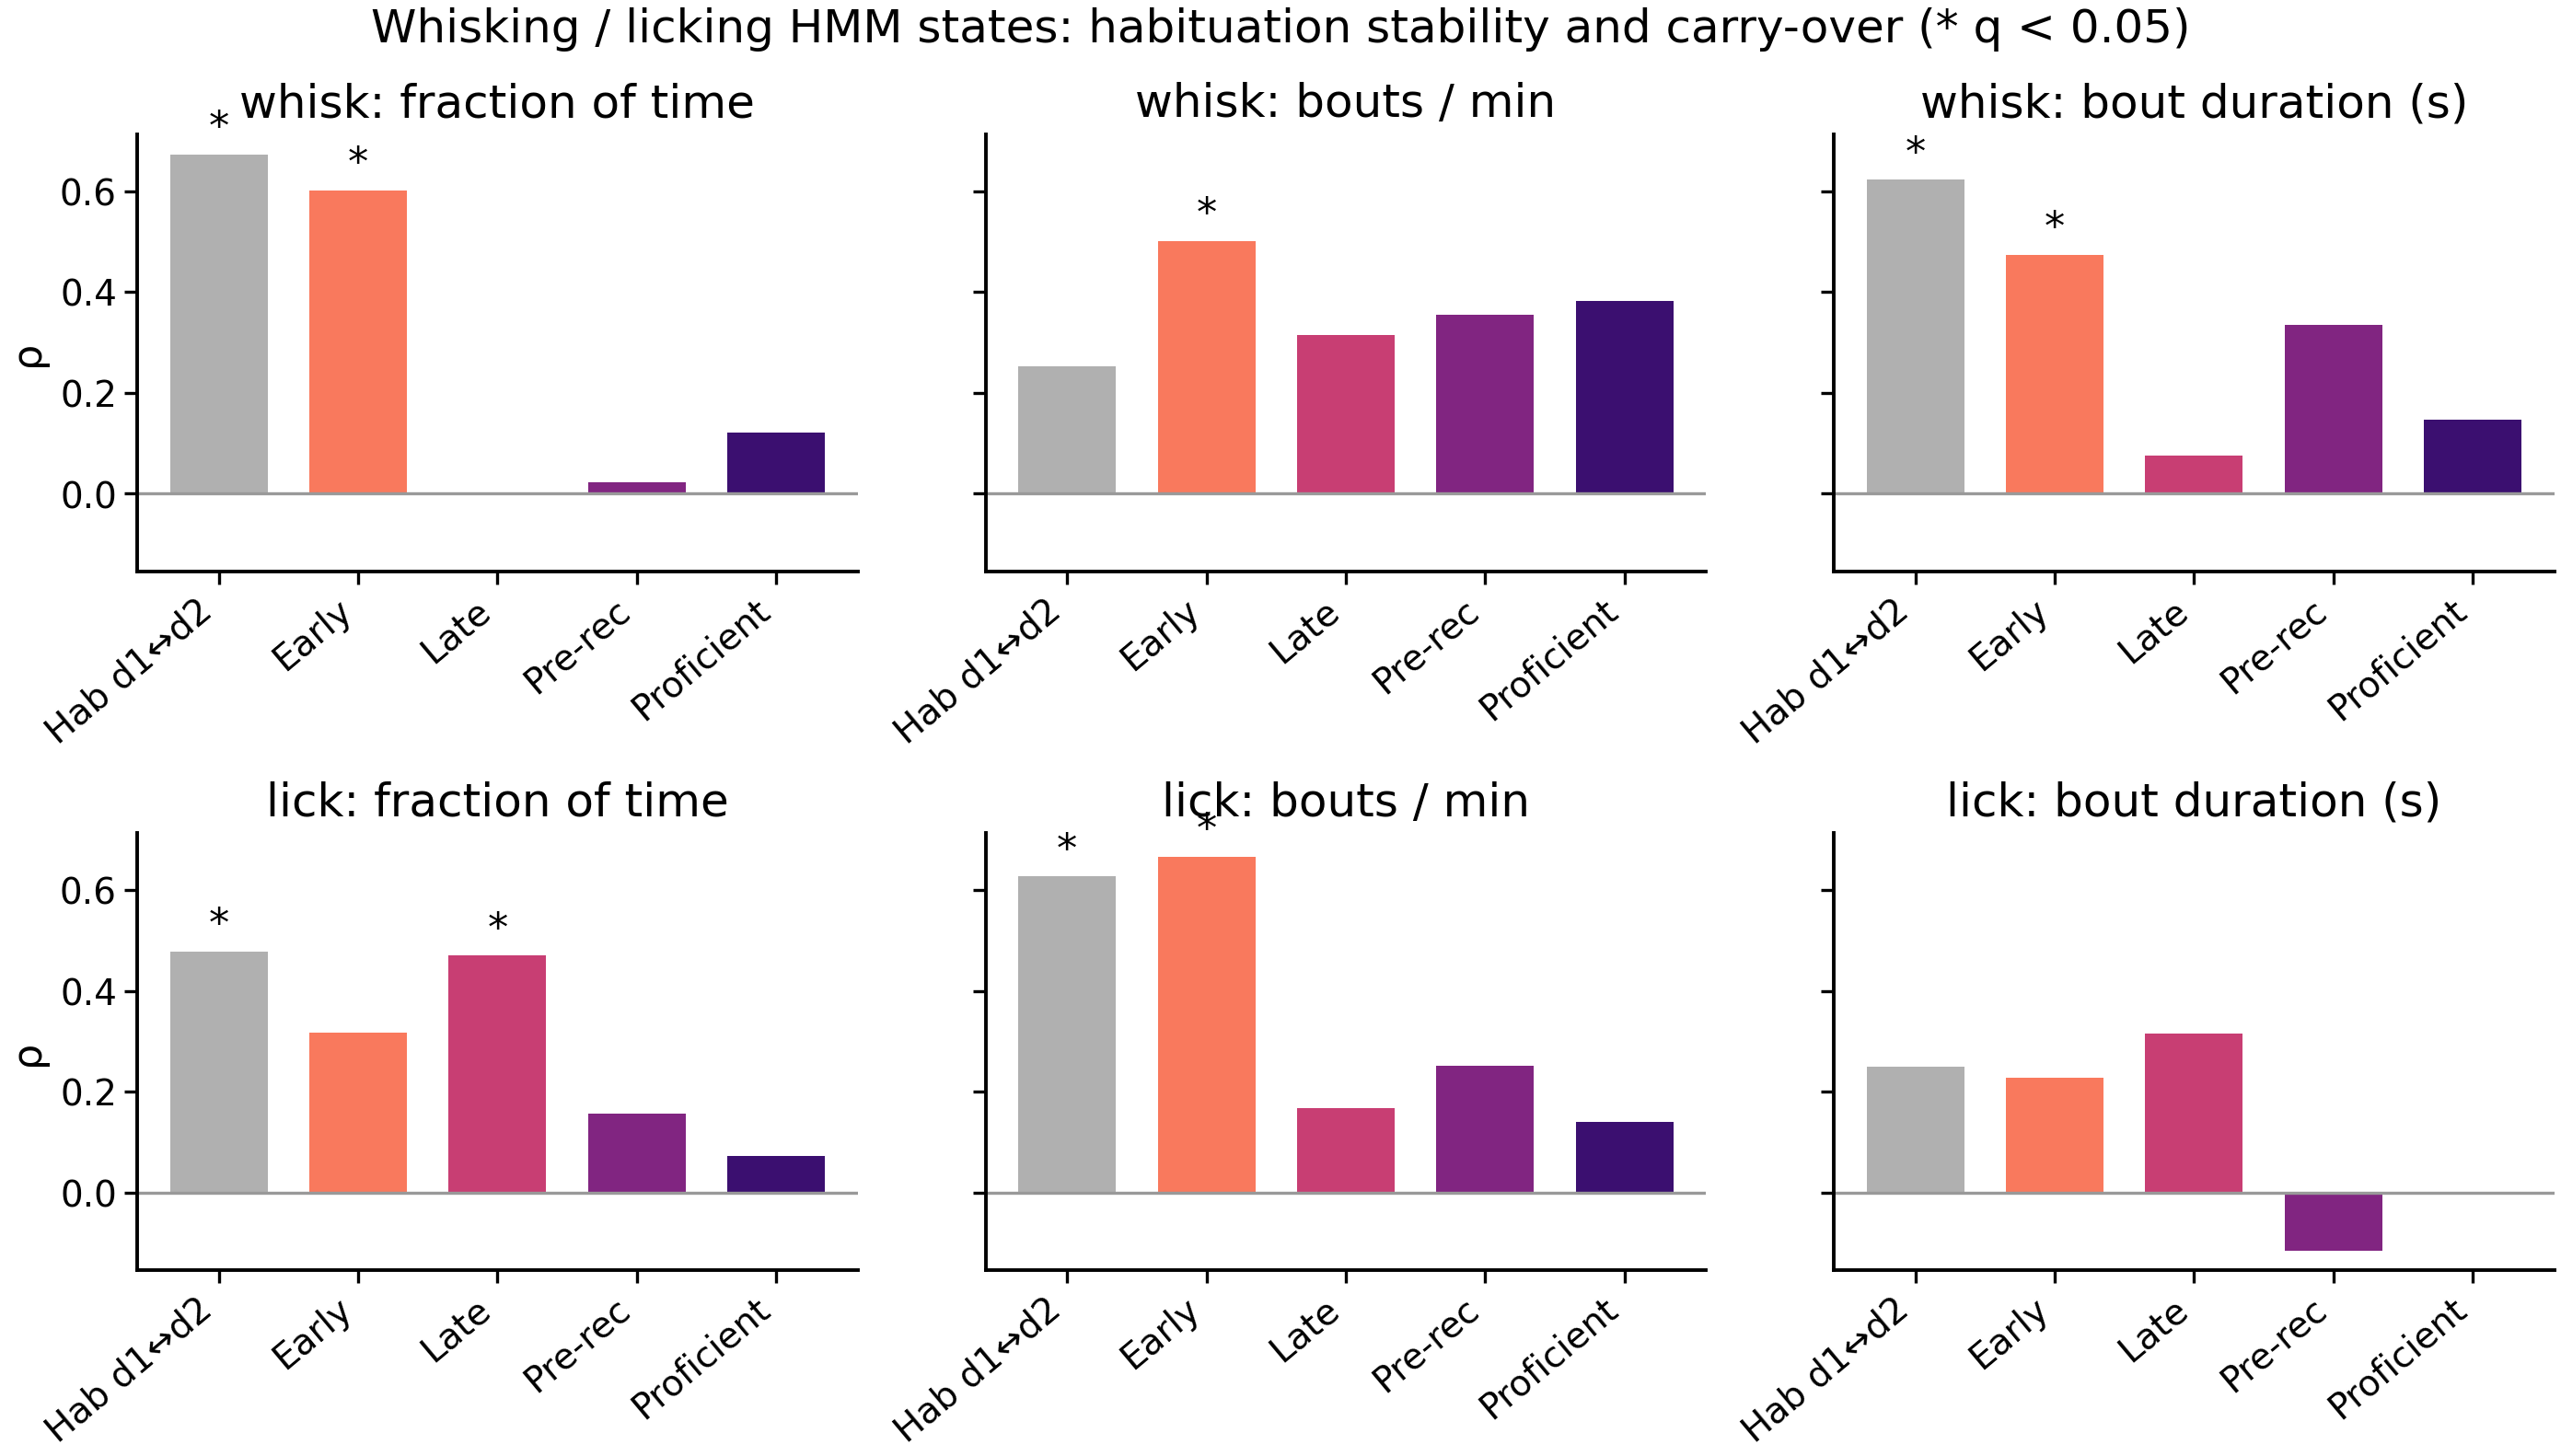

In [22]:
# ---- figure ---------------------------------------------------------------------------------
ps.use('paper')
fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.0), sharey=True, constrained_layout=True)
for r, sig in enumerate(['whisk', 'lick']):
    for c, m in enumerate(MEASURES):
        ax = axes[r, c]
        f = f'{sig}_{m}'
        s = stab[(stab['feature'] == f) & (stab['pair'] == 'day 1 vs 2')]
        d = cross[cross['feature'] == f].set_index('stage').reindex(ORDER[1:])
        xs = np.arange(len(ORDER))
        ys = np.r_[s[RHO].iloc[0] if len(s) else np.nan, d[RHO].to_numpy()]
        qs = np.r_[s[Q].iloc[0] if len(s) else np.nan, d[Q].to_numpy()]
        ax.bar(xs, ys, color=['#B0B0B0'] + [ps.TIMEPOINT.get(t, '0.5') for t in ORDER[1:]], width=0.7)
        for x, y_, q_ in zip(xs, ys, qs):
            if np.isfinite(q_) and q_ < 0.05:
                ax.text(x, y_ + 0.03, '*', ha='center')
        ax.axhline(0, color='0.6', lw=0.6)
        ax.set_xticks(xs); ax.set_xticklabels(['Hab d1↔d2'] + ORDER[1:], rotation=40, ha='right')
        ax.set_title(f'{sig}: {LABEL[m]}')
    axes[r, 0].set_ylabel('ρ' + (' (lab-controlled)' if LAB_CONTROL else ''))
fig.suptitle('Whisking / licking HMM states: habituation stability and carry-over (* q < 0.05)', fontsize=9)
FIG.mkdir(exist_ok=True)
fig.savefig(FIG / 'habituation_hmm_states.png', dpi=200)
plt.show()